Saving selected_dataset_pca.csv to selected_dataset_pca (1).csv
PCA Dataset Shape: (4159, 8)


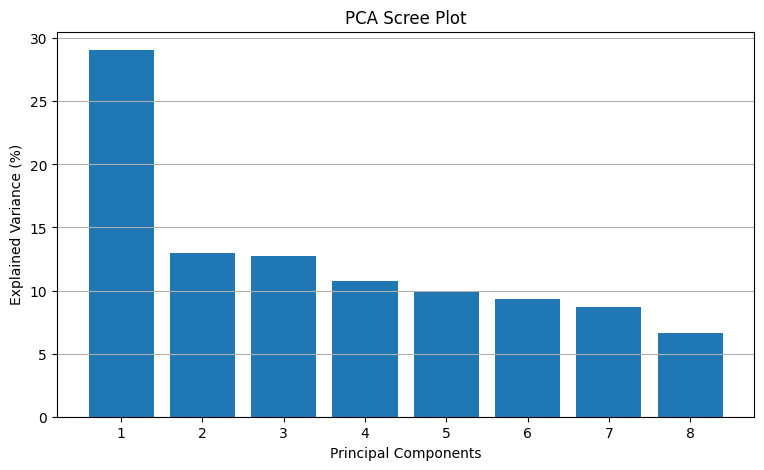

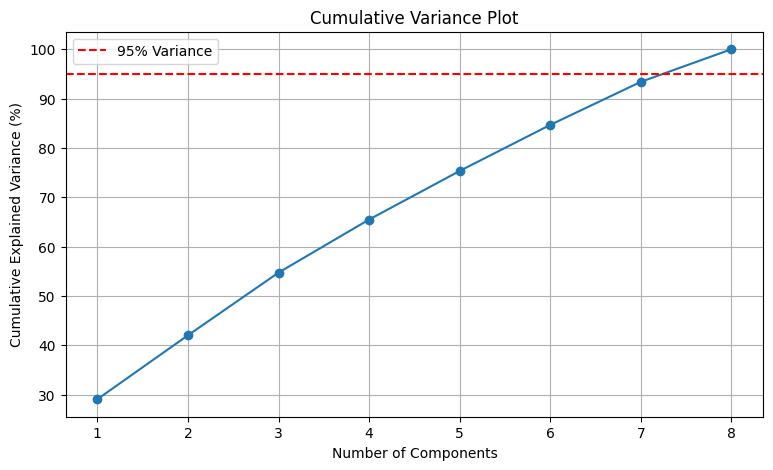

,Component,Individual Variance (%),Cumulative Variance (%)
0,PC1,29.06,29.06
1,PC2,12.96,42.02
2,PC3,12.70,54.72
3,PC4,10.76,65.48
4,PC5,9.85,75.33
5,PC6,9.34,84.67
6,PC7,8.72,93.39
7,PC8,6.61,100.00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from google.colab import files

# Step 1: Upload PCA Dataset
uploaded = files.upload()

filename = list(uploaded.keys())[0]
pca_dataset = pd.read_csv(filename)

print("PCA Dataset Shape:", pca_dataset.shape)

# Step 2: Calculate Explained Variance
pca = PCA()
pca.fit(pca_dataset)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Step 3: Scree Plot
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance * 100
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(axis='y')
plt.show()

# Step 4: Cumulative Variance Plot
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(
    y=95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Variance Plot")
plt.legend()
plt.grid()
plt.show()

# Step 5: Variance Table
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(explained_variance) + 1)],
    "Individual Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(variance_table.round(2))